In [50]:
!pip install -q pandas numpy matplotlib seaborn
!pip install -q langgraph
!pip install -q google-genai
!pip install -q reportlab

In [51]:
import pandas as pd
import numpy as np

data = {
    "Date": [
        "2026-10-01", "2026-10-02",
        "2026-10-03", "2026-10-04",
        "2026-10-05", "2026-10-06",
        "2026-10-07", "2026-10-08",
        "2026-10-09"
    ],
    "Category": [
        "Salary", "Rent", "Food",
        "Transport", "Shopping",
        "Entertainment", "Healthcare",
        "Education", "Investment"
    ],
    "Amount": [
        50000, 10000, 5000,
        2000, 4000, 2000, 1000,
        3000, 5000
    ],
    "Type": [
        "Income", "Expense", "Expense",
        "Expense", "Expense", "Expense",
        "Expense", "Expense", "Investment"
    ]
}

df = pd.DataFrame(data)

df["Date"] = pd.to_datetime(df["Date"])

display(df)

,Date,Category,Amount,Type
0,2026-10-01,Salary,50000,Income
1,2026-10-02,Rent,10000,Expense
2,2026-10-03,Food,5000,Expense
3,2026-10-04,Transport,2000,Expense
4,2026-10-05,Shopping,4000,Expense
5,2026-10-06,Entertainment,2000,Expense
6,2026-10-07,Healthcare,1000,Expense
7,2026-10-08,Education,3000,Expense
8,2026-10-09,Investment,5000,Investment


In [52]:
def budget_allocation_agent(income):

    budget = {
        "Needs": income * 0.50,
        "Wants": income * 0.30,
        "Savings": income * 0.20
    }

    return budget

# Calculate total income from the DataFrame to define expense_result
total_income = df[df["Type"] == "Income"]["Amount"].sum()
expense_result = {
    "total_income": total_income
}

budget_result = budget_allocation_agent(
    expense_result["total_income"]
)

print(budget_result)

{'Needs': np.float64(25000.0), 'Wants': np.float64(15000.0), 'Savings': np.float64(10000.0)}


In [53]:
!pip install -q google-genai

In [54]:
from google import genai
from google.colab import userdata

api_key = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents="Explain financial planning in 3 sentences."
)

print(response.text)

Financial planning is the ongoing process of evaluating your current monetary situation to set realistic short- and long-term goals. It involves creating a strategic roadmap—covering budgeting, saving, investing, and risk management—to navigate life's milestones and secure your future. Ultimately, it provides peace of mind by ensuring your money is actively working to support the lifestyle and security you desire.


In [55]:
MODEL_NAME = "gemini-3.5-flash-lite"

In [56]:
MODEL_NAME = "gemini-3.5-flash-lite"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="Explain financial planning in 3 simple sentences."
)

print(response.text)

Financial planning is the process of setting clear goals for your money, assessing your current income and expenses, and creating a realistic roadmap to achieve those goals over time.


In [57]:
def financial_report_agent(expense_result, budget_result):

    prompt = f"""
    You are a professional financial planning assistant.

    Generate a financial report using the following data.

    EXPENSE ANALYSIS:
    {expense_result}

    BUDGET ALLOCATION:
    {budget_result}

    Include:

    1. Financial Summary
    2. Income Analysis
    3. Expense Analysis
    4. Budget Recommendations
    5. Savings Opportunities
    6. Financial Improvement Suggestions

    Use Indian Rupees (INR).
    Use simple professional language.
    Do not invent financial figures.
    """

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response.text

In [58]:
report = financial_report_agent(
    expense_result,
    budget_result
)

print(report)

# Professional Financial Report

## 1. Financial Summary
This financial report provides an overview of your current financial standing based on your reported income and budget allocation. 
* **Total Monthly Income:** ₹50,000
* **Total Monthly Allocation (Expenses + Savings):** ₹50,000
* **Budget Distribution:** Needs (50%), Wants (30%), Savings (20%)

## 2. Income Analysis
* **Total Income:** ₹50,000
* Your primary income serves as the baseline for all monthly financial planning. Maintaining a steady income is essential for supporting your current budget allocation across needs, wants, and savings.

## 3. Expense Analysis
Your total expenses are divided into essential needs and discretionary wants, totaling ₹40,000 (80% of your total income).
* **Needs (Essential Expenses):** ₹25,000 (50% of income)
  * This covers necessary living expenses such as housing, utilities, groceries, healthcare, and basic transportation.
* **Wants (Discretionary Expenses):** ₹15,000 (30% of income)
  * This

In [59]:
def financial_report_agent(expense_result, budget_result):

    prompt = f"""
    You are a professional financial analyst.

    Generate a detailed financial report using
    the following actual financial data.

    ACTUAL EXPENSE ANALYSIS:
    {expense_result}

    RECOMMENDED BUDGET:
    {budget_result}

    IMPORTANT RULES:

    1. Never confuse actual expenses with recommended budgets.
    2. Calculate actual expenses using the expense analysis.
    3. Clearly distinguish actual savings from planned savings.
    4. Do not invent financial figures.
    5. Explain any remaining unallocated cash.

    Generate the following sections:

    1. Financial Summary
    2. Income Analysis
    3. Actual Expense Analysis
    4. Recommended Budget Allocation
    5. Savings and Investment Analysis
    6. Financial Improvement Suggestions

    Use Indian Rupees (INR).

    Write in professional language.
    Include numerical comparisons wherever possible.
    """

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response.text

In [60]:
def financial_report_agent(expense_result, budget_result):

    prompt = f"""
    You are a professional financial analyst.

    Generate a detailed financial report using
    the following actual financial data.

    ACTUAL EXPENSE ANALYSIS:
    {expense_result}

    RECOMMENDED BUDGET:
    {budget_result}

    IMPORTANT RULES:

    1. Never confuse actual expenses with recommended budgets.
    2. Calculate actual expenses using the expense analysis.
    3. Clearly distinguish actual savings from planned savings.
    4. Do not invent financial figures.
    5. Explain any remaining unallocated cash.

    Generate the following sections:

    1. Financial Summary
    2. Income Analysis
    3. Actual Expense Analysis
    4. Recommended Budget Allocation
    5. Savings and Investment Analysis
    6. Financial Improvement Suggestions

    Use Indian Rupees (INR).

    Write in professional language.
    Include numerical comparisons wherever possible.
    """

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response.text

In [61]:
report = financial_report_agent(
    expense_result,
    budget_result
)

print(report)

# Comprehensive Financial Analysis Report

**Prepared by:** Professional Financial Analyst  
**Currency:** Indian Rupees (INR)  
**Date:** Current Period  

---

## 1. Financial Summary

This financial report provides a rigorous evaluation of the subject’s current financial standing based strictly on the provided data. The total income recorded for the period stands at **₹50,000**. Against this total income, a structured budgetary framework has been recommended, totaling **₹50,000** (allocated across Needs at ₹25,000, Wants at ₹15,000, and Savings at ₹10,000). 

A critical distinction must be maintained between the macro-level income, the strictly defined recommended budget allocations, and actual tracked expenses. 

---

## 2. Income Analysis

* **Total Income:** **₹50,000**

The baseline inflow for the evaluated financial period is strictly capped at ₹50,000. This figure serves as the foundational constraint and benchmark against which all recommended budget allocations and savings t

In [62]:
print("EXPENSE RESULT:")
print(expense_result)

print("\nBUDGET RESULT:")
print(budget_result)

print("\nDATASET:")
display(df)

EXPENSE RESULT:
{'total_income': np.int64(50000)}

BUDGET RESULT:
{'Needs': np.float64(25000.0), 'Wants': np.float64(15000.0), 'Savings': np.float64(10000.0)}

DATASET:


,Date,Category,Amount,Type
0,2026-10-01,Salary,50000,Income
1,2026-10-02,Rent,10000,Expense
2,2026-10-03,Food,5000,Expense
3,2026-10-04,Transport,2000,Expense
4,2026-10-05,Shopping,4000,Expense
5,2026-10-06,Entertainment,2000,Expense
6,2026-10-07,Healthcare,1000,Expense
7,2026-10-08,Education,3000,Expense
8,2026-10-09,Investment,5000,Investment


In [63]:
import json

def expense_analysis_agent(df):
    # Summarize raw data for LLM context
    raw_data_summary = df.to_dict(orient='records')

    prompt = f"""
    You are an expert Financial Analysis Agent.
    Analyze the following financial transactions data and return a strictly valid JSON object matching the schema below.
    Do not include any markdown wrap (like ```json) or backticks in your output.

    Transactions:
    {raw_data_summary}

    Desired JSON Schema output:
    {{
        "total_income": float,
        "total_expenses": float,
        "total_investments": float,
        "remaining_cash": float,
        "category_breakdown": {{
            "CategoryName": float,
            ...
        }}
    }}
    """

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    try:
        # Clean response string of any markdown code blocks if present
        clean_text = response.text.strip().replace('```json', '').replace('```', '')
        analysis = json.loads(clean_text)
    except Exception as e:
        # Fallback to programmatic calculation if JSON parsing fails
        income = df[df["Type"] == "Income"]["Amount"].sum()
        expenses = df[df["Type"] == "Expense"]
        investments = df[df["Type"] == "Investment"]
        total_expenses = expenses["Amount"].sum()
        total_investments = investments["Amount"].sum()
        remaining_cash = income - total_expenses - total_investments
        category_expenses = expenses.groupby("Category")["Amount"].sum().to_dict()

        analysis = {
            "total_income": float(income),
            "total_expenses": float(total_expenses),
            "total_investments": float(total_investments),
            "remaining_cash": float(remaining_cash),
            "category_breakdown": category_expenses
        }

    return analysis

expense_result = expense_analysis_agent(df)
print(expense_result)

{'total_income': 50000.0, 'total_expenses': 27000.0, 'total_investments': 5000.0, 'remaining_cash': 18000.0, 'category_breakdown': {'Salary': 50000.0, 'Rent': 10000.0, 'Food': 5000.0, 'Transport': 2000.0, 'Shopping': 4000.0, 'Entertainment': 2000.0, 'Healthcare': 1000.0, 'Education': 3000.0, 'Investment': 5000.0}}


In [64]:
def financial_report_agent(expense_result, budget_result):

    prompt = f"""
    You are a professional financial analyst.

    Generate a financial analysis report.

    ACTUAL FINANCIAL DATA:
    {expense_result}

    RECOMMENDED BUDGET:
    {budget_result}

    Generate these sections:

    1. Financial Summary
    2. Income Analysis
    3. Actual Expense Analysis
    4. Budget Allocation
    5. Savings and Investment Analysis
    6. Financial Improvement Suggestions

    IMPORTANT:

    - Actual expenses and planned budgets are different.
    - Never treat recommended allocations as actual spending.
    - Calculate remaining cash from actual income,
      expenses and investments.
    - Do not call remaining cash actual savings.
    - Clearly distinguish planned savings from actual savings.
    - Compare actual spending with budget recommendations
      only where categories can be reliably mapped.
    - Never invent missing financial figures.

    Use INR and professional language.
    """

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response.text


report = financial_report_agent(
    expense_result,
    budget_result
)

print(report)

# Professional Financial Analysis Report

## 1. Financial Summary
This financial analysis report evaluates the financial standing based on the provided actual financial data and recommended budget allocations. 

For the analyzed period, the total recorded income stands at ₹50,000.00, against total actual expenses of ₹27,000.00 and total actual investments of ₹5,000.00. The resulting remaining cash, calculated by subtracting actual expenses and investments from the total income, is ₹18,000.00. It is important to note that remaining cash is the liquid capital left over after all expenditures and capital deployments, and it should not be conflated with actual savings. 

---

## 2. Income Analysis
The total income for the period is ₹50,000.00. Based on the provided category breakdown, the entirety of this income is derived from a single primary source:
* **Salary:** ₹50,000.00 (100% of total income)

The income stream is currently concentrated in employment earnings, indicating a reliance 

In [65]:
!pip install -q langgraph

In [66]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

print("LangGraph imported successfully!")

LangGraph imported successfully!


In [67]:
from typing import TypedDict

class FinanceState(TypedDict):
    df: object
    expense_result: dict
    budget_result: dict
    report: str

In [68]:
# Agent 1 Node
def expense_node(state: FinanceState):

    print("Expense Analysis Agent is running...")

    result = expense_analysis_agent(state["df"])

    return {
        "expense_result": result
    }


# Agent 2 Node
def budget_node(state: FinanceState):

    print("Budget Allocation Agent is running...")

    income = state["expense_result"]["total_income"]

    result = budget_allocation_agent(income)

    return {
        "budget_result": result
    }


# Agent 3 Node
def report_node(state: FinanceState):

    print("Financial Report Agent is running...")

    result = financial_report_agent(
        state["expense_result"],
        state["budget_result"]
    )

    return {
        "report": result
    }

print("All three agent nodes created successfully!")

All three agent nodes created successfully!


In [69]:
from langgraph.graph import StateGraph, START, END

# Create workflow
workflow = StateGraph(FinanceState)

# Register agents
workflow.add_node("expense_agent", expense_node)
workflow.add_node("budget_agent", budget_node)
workflow.add_node("report_agent", report_node)

# Define execution order
workflow.add_edge(START, "expense_agent")

workflow.add_edge(
    "expense_agent",
    "budget_agent"
)

workflow.add_edge(
    "budget_agent",
    "report_agent"
)

workflow.add_edge("report_agent", END)

# Compile workflow
finance_system = workflow.compile()

print("Financial Multi-Agent System compiled successfully!")

Financial Multi-Agent System compiled successfully!


In [70]:
initial_state = {
    "df": df,
    "expense_result": {},
    "budget_result": {},
    "report": ""
}

final_result = finance_system.invoke(initial_state)

print("\n========== FINANCIAL REPORT ==========\n")

print(final_result["report"])

Expense Analysis Agent is running...
Budget Allocation Agent is running...
Financial Report Agent is running...

========== FINANCIAL REPORT ==========

# Financial Analysis Report

**Prepared by:** Professional Financial Analyst  
**Currency:** INR (₹)  

---

## 1. Financial Summary

This financial analysis report provides a comprehensive evaluation of the client's financial standing based on actual recorded income, expenses, and investments, contrasted against the recommended budgetary framework. 

During the analyzed period, the total recorded income stands at ₹50,000.0, while total actual expenses amount to ₹27,000.0. Additionally, ₹5,000.0 has been allocated toward investments. After accounting for all outflows (expenses and investments) from the total income, the resulting remaining cash is ₹18,000.0. It is crucial to note that remaining cash represents unallocated liquidity and should not be misconstrued as actual net savings.

---

## 2. Income Analysis

* **Total Income:** ₹5

In [71]:
print("========== AGENT 1 OUTPUT ==========")
print(final_result["expense_result"])

print("\n========== AGENT 2 OUTPUT ==========")
print(final_result["budget_result"])

print("\n========== AGENT 3 OUTPUT ==========")
print(final_result["report"])

========== AGENT 1 OUTPUT ==========
{'total_income': 50000.0, 'total_expenses': 27000.0, 'total_investments': 5000.0, 'remaining_cash': 18000.0, 'category_breakdown': {'Salary': 50000.0, 'Rent': 10000.0, 'Food': 5000.0, 'Transport': 2000.0, 'Shopping': 4000.0, 'Entertainment': 2000.0, 'Healthcare': 1000.0, 'Education': 3000.0, 'Investment': 5000.0}}

========== AGENT 2 OUTPUT ==========
{'Needs': 25000.0, 'Wants': 15000.0, 'Savings': 10000.0}

========== AGENT 3 OUTPUT ==========
# Financial Analysis Report

**Prepared by:** Professional Financial Analyst  
**Currency:** INR (₹)  

---

## 1. Financial Summary

This financial analysis report provides a comprehensive evaluation of the client's financial standing based on actual recorded income, expenses, and investments, contrasted against the recommended budgetary framework. 

During the analyzed period, the total recorded income stands at ₹50,000.0, while total actual expenses amount to ₹27,000.0. Additionally, ₹5,000.0 has been allo

In [72]:
!pip install -q reportlab

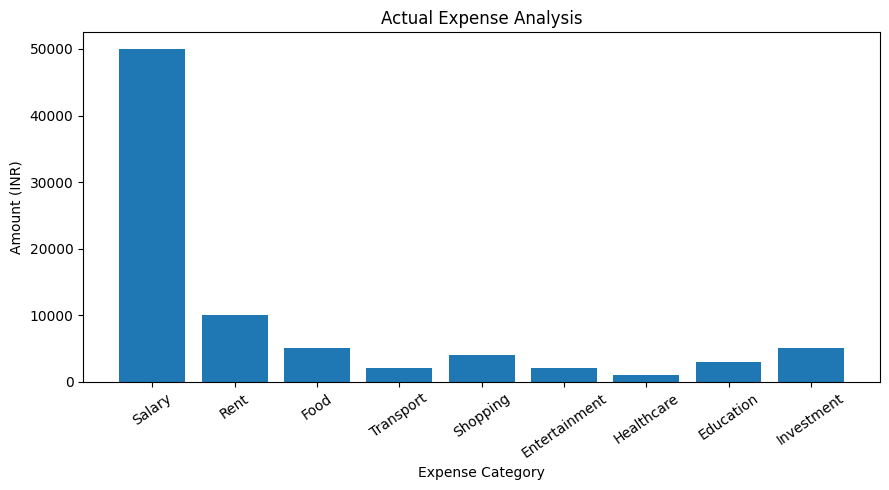

In [73]:
import matplotlib.pyplot as plt

category_data = final_result["expense_result"]["category_breakdown"]

plt.figure(figsize=(9, 5))

plt.bar(
    category_data.keys(),
    category_data.values()
)

plt.title("Actual Expense Analysis")
plt.xlabel("Expense Category")
plt.ylabel("Amount (INR)")

plt.xticks(rotation=35)
plt.tight_layout()

plt.savefig("expense_chart.png", dpi=150)

plt.show()

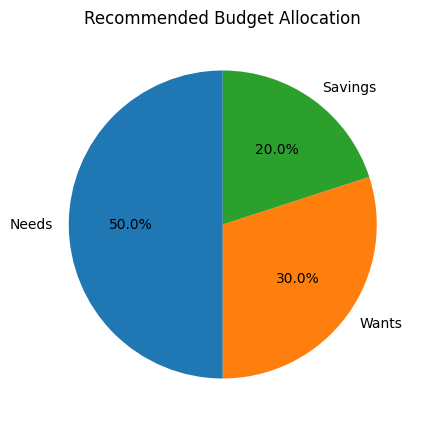

In [74]:
budget = final_result["budget_result"]

plt.figure(figsize=(7, 5))

plt.pie(
    budget.values(),
    labels=budget.keys(),
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Recommended Budget Allocation")

plt.savefig("budget_chart.png", dpi=150)

plt.show()

In [75]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image, Table, TableStyle, PageBreak
)
from reportlab.lib.units import inch
from reportlab.lib.colors import HexColor
from xml.sax.saxutils import escape
import os
import re

# Get data directly from LangGraph
expense = final_result["expense_result"]
budget = final_result["budget_result"]
report = final_result["report"]

# Create PDF
pdf_file = "Financial_Analysis_Report.pdf"

doc = SimpleDocTemplate(
    pdf_file,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()
story = []

# Title
story.append(Paragraph(
    "FINANCIAL PLANNING REPORT",
    styles["Title"]
))
story.append(Paragraph(
    "AI-Powered Multi-Agent Financial Analysis System",
    styles["Heading2"]
))
story.append(Spacer(1, 20))

# Financial summary
story.append(Paragraph(
    "1. Financial Summary",
    styles["Heading2"]
))

summary = [
    ["Financial Metric", "Amount (INR)"],
    ["Total Income", f"Rs. {expense['total_income']:,.2f}"],
    ["Actual Expenses", f"Rs. {expense['total_expenses']:,.2f}"],
    ["Investments", f"Rs. {expense['total_investments']:,.2f}"],
    ["Remaining Cash", f"Rs. {expense['remaining_cash']:,.2f}"]
]

table = Table(summary, colWidths=[250, 180])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), HexColor("#17365D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 9),
    ("BACKGROUND", (0, 1), (-1, -1), HexColor("#F1F5F9"))
]))

story.append(table)
story.append(Spacer(1, 20))

# Expense chart
story.append(Paragraph(
    "2. Expense Distribution",
    styles["Heading2"]
))

if os.path.exists("expense_chart.png"):
    story.append(Image(
        "expense_chart.png",
        width=450,
        height=250
    ))

story.append(Spacer(1, 15))

# Budget chart
story.append(Paragraph(
    "3. Recommended Budget Allocation",
    styles["Heading2"]
))

if os.path.exists("budget_chart.png"):
    story.append(Image(
        "budget_chart.png",
        width=350,
        height=250
    ))

story.append(PageBreak())

# AI generated report
story.append(Paragraph(
    "4. AI-Generated Financial Analysis",
    styles["Heading1"]
))

for line in report.splitlines():

    line = line.strip()

    if not line:
        story.append(Spacer(1, 5))
        continue

    if line.startswith("#"):
        heading = line.lstrip("#").strip()
        story.append(Paragraph(
            escape(heading),
            styles["Heading2"]
        ))

    elif line.startswith("- ") or line.startswith("* "):
        story.append(Paragraph(
            "&bull; " + escape(line[2:]),
            styles["BodyText"]
        ))

    else:
        clean_line = re.sub(r"\*\*(.*?)\*\*", r"<b>\1</b>", line)
        story.append(Paragraph(
            clean_line,
            styles["BodyText"]
        ))
        story.append(Spacer(1, 5))

# Footer
def footer(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.drawCentredString(
        A4[0] / 2,
        20,
        f"Financial Planning System | Page {doc.page}"
    )
    canvas.restoreState()

doc.build(
    story,
    onFirstPage=footer,
    onLaterPages=footer
)

print("PDF generated successfully!")
print("Filename:", pdf_file)

PDF generated successfully!
Filename: Financial_Analysis_Report.pdf


In [76]:
from google.colab import files

files.download("Financial_Analysis_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [77]:
from google.colab import files

files.download("Financial_Analysis_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [78]:
!pip install -q gradio

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr

def run_financial_dashboard(file):

    if file is None:
        raise gr.Error("Please upload a CSV file.")

    # Read CSV
    data = pd.read_csv(file)

    # Validate columns
    required = ["Date", "Category", "Amount", "Type"]

    if not all(col in data.columns for col in required):
        raise gr.Error(f"CSV must contain: {required}")

    # Preprocessing
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    data["Amount"] = pd.to_numeric(data["Amount"], errors="coerce")
    data["Type"] = data["Type"].astype(str).str.strip().str.title()
    data["Category"] = data["Category"].astype(str).str.strip()

    if data[required].isnull().any().any():
        raise gr.Error("CSV contains missing or invalid values.")

    if (data["Amount"] < 0).any():
        raise gr.Error("Transaction amounts cannot be negative.")

    allowed_types = ["Income", "Expense", "Investment"]

    if not data["Type"].isin(allowed_types).all():
        raise gr.Error(f"Transaction types must be {allowed_types}")

    if not (data["Type"] == "Income").any():
        raise gr.Error("At least one income transaction is required.")

    # Execute LangGraph
    result = finance_system.invoke({
        "df": data,
        "expense_result": {},
        "budget_result": {},
        "report": ""
    })

    expense = result["expense_result"]
    budget = result["budget_result"]
    report = result["report"]

    # Expense chart
    expense_fig, ax = plt.subplots(figsize=(9, 4))

    categories = list(expense["category_breakdown"].keys())
    amounts = list(expense["category_breakdown"].values())

    ax.bar(categories, amounts)
    ax.set_title("Actual Expense Analysis")
    ax.set_ylabel("Amount (INR)")
    ax.tick_params(axis="x", rotation=35)
    expense_fig.tight_layout()

    # Budget chart
    budget_fig, ax = plt.subplots(figsize=(6, 4))

    ax.pie(
        budget.values(),
        labels=budget.keys(),
        autopct="%1.1f%%"
    )

    ax.set_title("Recommended Budget Allocation")

    # Summary
    summary = f"""
    ## Financial Overview

    - **Total Income:** ₹{expense['total_income']:,.2f}
    - **Actual Expenses:** ₹{expense['total_expenses']:,.2f}
    - **Investments:** ₹{expense['total_investments']:,.2f}
    - **Remaining Cash:** ₹{expense['remaining_cash']:,.2f}

    ### Recommended Budget

    - Needs: ₹{budget['Needs']:,.2f}
    - Wants: ₹{budget['Wants']:,.2f}
    - Savings: ₹{budget['Savings']:,.2f}
    """

    return summary, expense_fig, budget_fig, report

In [ ]:
with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Financial Planning Multi-Agent System"
) as demo:

    gr.Markdown(
        """
        # 💰 Financial Planning Multi-Agent System

        ### AI-Powered Financial Analysis and Budget Planning

        Upload your financial transaction CSV to analyze
        expenses, allocate budgets and generate reports.
        """
    )

    file_input = gr.File(
        label="Upload Financial CSV",
        file_types=[".csv"],
        type="filepath"
    )

    run_button = gr.Button(
        "Analyze My Finances",
        variant="primary"
    )

    summary_output = gr.Markdown(label="Financial Summary")

    with gr.Row():
        expense_chart = gr.Plot(label="Expense Analysis")
        budget_chart = gr.Plot(label="Budget Allocation")

    report_output = gr.Markdown(
        label="AI Financial Report"
    )

    run_button.click(
        fn=run_financial_dashboard,
        inputs=file_input,
        outputs=[
            summary_output,
            expense_chart,
            budget_chart,
            report_output
        ]
    )

demo.launch(share=True, debug=True)

/tmp/ipykernel_706/2787475569.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://a0d409db38907ee76d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Expense Analysis Agent is running...
Budget Allocation Agent is running...
Financial Report Agent is running...
Expense Analysis Agent is running...
Budget Allocation Agent is running...
Financial Report Agent is running...
